# HCAI 4302 – Homework 2
**Gemar Johnston** **Fundamentals of Human-Centered AI Models**

Part 1 clusters countries (WDI 2022) with PCA, hierarchical clustering and K-means. Part 2 explores the FICO loan data and predicts interest rates with linear regression.

**Data checks I did before modelling** (a few things in the files would have quietly broken results):
- `merged_data.csv` has a `date` column that is 2022 for every row. Zero variance, so it is dropped before scaling.
- The income cut-offs in the prompt leave a gap between $1,145 and $1,146. GNI is continuous, so I use right-closed bins (`<= 1145`, `<= 4515`, `<= 14005`) and nothing falls through.
- The four income dummies always sum to 1, so they are perfectly collinear. That is fine for PCA and clustering, but I come back to it when interpreting loadings.
- `ficoscores.csv` has impossible values (FICO above 850, two interest rates entered as percentages) and two missing `meets_credit_criteria` values. Details in Task 7.
# Note: I ran into an issue with seaborn dependency and decided to use matplotlib. I still am able to run my program.

In [ ]:
#Setting up the environment with this cell of code.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

plt.rcParams.update({"axes.grid": True, "grid.alpha": .35, "axes.spines.top": False,
                    "axes.spines.right": False, "figure.dpi": 100})
SEED = 42


def find_file(*names):
    # tolerate the "-1" suffix browsers add to repeated downloads
    for n in names:
        if Path(n).exists():
            return n
    raise FileNotFoundError(f"none of {names} found in {Path.cwd()}")


def heatmap(data, ax, fmt=".2f", label="correlation"):
    # annotated heatmap in plain matplotlib, diverging scale fixed to [-1, 1]
    im = ax.imshow(data.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(data.columns, rotation=90)
    ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(data.index)
    ax.grid(False)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.values[i, j]
            ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > .6 else "black")
    plt.colorbar(im, ax=ax).set_label(label)

# Part 1 – Clustering Analysis (WDI 2022)

In [ ]:
raw = pd.read_csv(find_file("merged_data.csv", "merged_data-1.csv"))
print(raw.shape, "| duplicated countries:", raw["country"].duplicated().sum(),
      "| missing values:", int(raw.isna().sum().sum()))
print("unique values in date:", raw["date"].unique())

# Country becomes the index so labels survive every transformation
wdi = raw.drop(columns="date").set_index("country")
wdi.describe().T.round(2)

(128, 10) | duplicated countries: 0 | missing values: 0
unique values in date: [2022]


,count,mean,std,min,25%,50%,75%,max
Control of Corruption,128.0,0.00,1.00,-1.60,-0.70,-0.27,0.67,2.40
Rule of Law,128.0,0.02,0.95,-1.80,-0.73,-0.11,0.71,1.96
GNI_per_capita,128.0,15040.25,19951.43,254.97,2050.65,5911.08,18756.95,105005.99
Inflation,128.0,12.02,18.14,1.35,5.78,8.24,11.55,171.21
Trade_as_percent_GDP,128.0,99.67,57.79,26.60,60.98,88.27,123.36,388.51
Unemployment_rate,128.0,6.93,5.51,0.23,3.29,5.17,8.85,33.27
GHG_Emissions_per_Capita,128.0,6.64,6.68,0.53,2.21,4.77,8.47,41.00
Urban_pop_%,128.0,62.28,21.53,14.42,44.76,64.58,80.59,100.00


## Task 1 – New variables

Income level from GNI per capita, one dummy per level, then GNI is dropped.

In [3]:
bins = [-np.inf, 1145, 4515, 14005, np.inf]
names = ["Low", "Lower-middle", "Upper-middle", "High"]
wdi["Income_Level"] = pd.cut(wdi["GNI_per_capita"], bins=bins, labels=names)

print(wdi["Income_Level"].value_counts().reindex(names))

dummies = pd.get_dummies(wdi["Income_Level"], prefix="Income", dtype=int)
X = pd.concat([wdi.drop(columns=["GNI_per_capita", "Income_Level"]), dummies], axis=1)

assert "GNI_per_capita" not in X.columns and X.isna().sum().sum() == 0
X.head()

Income_Level
Low             16
Lower-middle    40
Upper-middle    30
High            42
Name: count, dtype: int64


,Control of Corruption,Rule of Law,Inflation,Trade_as_percent_GDP,Unemployment_rate,GHG_Emissions_per_Capita,Urban_pop_%,Income_Low,Income_Lower-middle,Income_Upper-middle,Income_High
country,,,,,,,,,,,
Albania,-0.408189,-0.165585,6.725203,84.698064,10.137,2.812410,63.799,0,0,1,0
Algeria,-0.638041,-0.833260,9.265516,51.202376,12.346,5.787845,74.772,0,1,0,0
Angola,-0.612376,-1.022036,21.355290,69.691071,14.602,1.886088,68.081,0,1,0,0
Armenia,0.027907,-0.169516,8.640911,101.410778,13.379,3.490671,63.573,0,0,1,0
Australia,1.764367,1.508819,6.594097,45.821770,3.728,21.872898,86.488,0,0,0,1


## Task 2 – PCA (5 components)

I standardize first because the features live on very different scales (urban % is 0–100, the governance scores are roughly –2 to 2, and the dummies are 0/1). Without scaling, PC1 would just follow whichever column has the largest variance.

For the plots I use variable component **correlations** (loading × √eigenvalue). They are bounded by ±1, so the correlation circle and heatmap are on the same footing.

In [ ]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

pca = PCA(n_components=5, random_state=SEED)
scores = pca.fit_transform(Xs)
pcs = [f"PC{i+1}" for i in range(5)]

# Correlation of each original variable with each component.
corr = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_),
                    index=X.columns, columns=pcs)

evr = pd.DataFrame({"explained": pca.explained_variance_ratio_,
                    "cumulative": pca.explained_variance_ratio_.cumsum()}, index=pcs)
evr.round(3)

,explained,cumulative
PC1,0.364,0.364
PC2,0.157,0.520
PC3,0.124,0.645
PC4,0.086,0.730
PC5,0.077,0.807


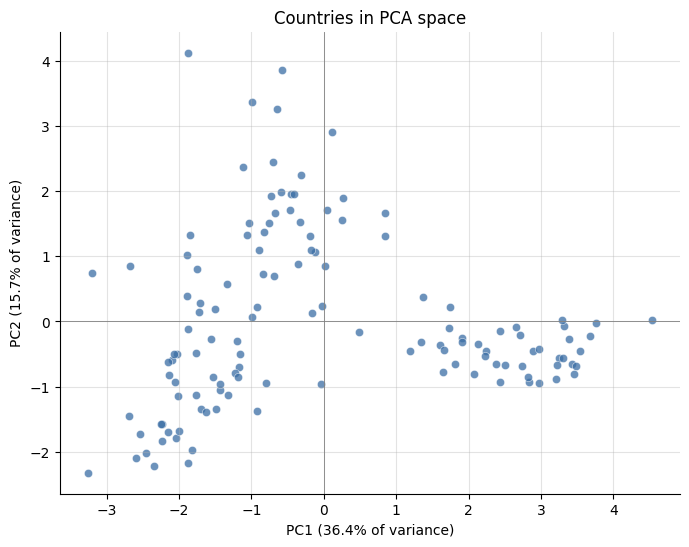

In [ ]:
# The PCA scatter
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(scores[:, 0], scores[:, 1], s=35, alpha=.75, color="#3b6ea5", edgecolor="white", linewidth=.4)
ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6)
ax.set_xlabel(f"PC1 ({evr.explained.iloc[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({evr.explained.iloc[1]:.1%} of variance)")
ax.set_title("Countries in PCA space")
plt.show()

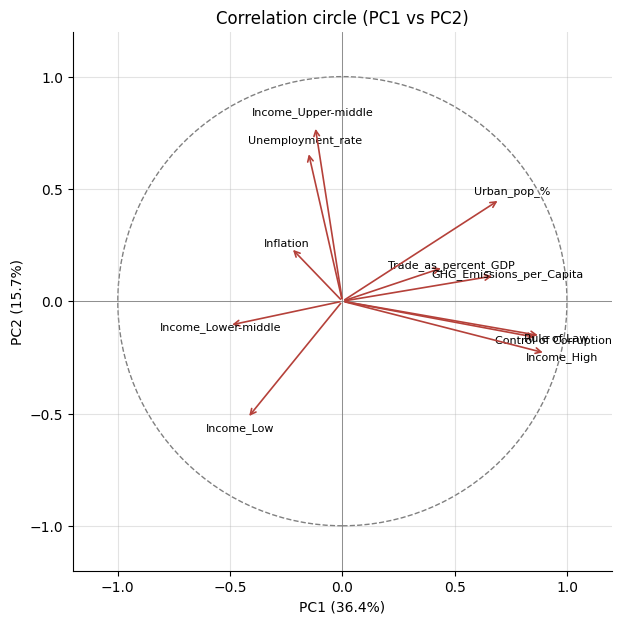

In [ ]:
# Correlation circle
def corr_circle(ax, corr, evr):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", ls="--"))
    for var, (x, y) in corr[["PC1", "PC2"]].iterrows():
        ax.annotate("", xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="#b5413a", lw=1.2))
        ax.text(x * 1.08, y * 1.08, var, fontsize=8, ha="center", va="center")
    ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6)
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal")
    ax.set_xlabel(f"PC1 ({evr.explained.iloc[0]:.1%})"); ax.set_ylabel(f"PC2 ({evr.explained.iloc[1]:.1%})")

fig, ax = plt.subplots(figsize=(7, 7))
corr_circle(ax, corr, evr)
ax.set_title("Correlation circle (PC1 vs PC2)")
plt.show()

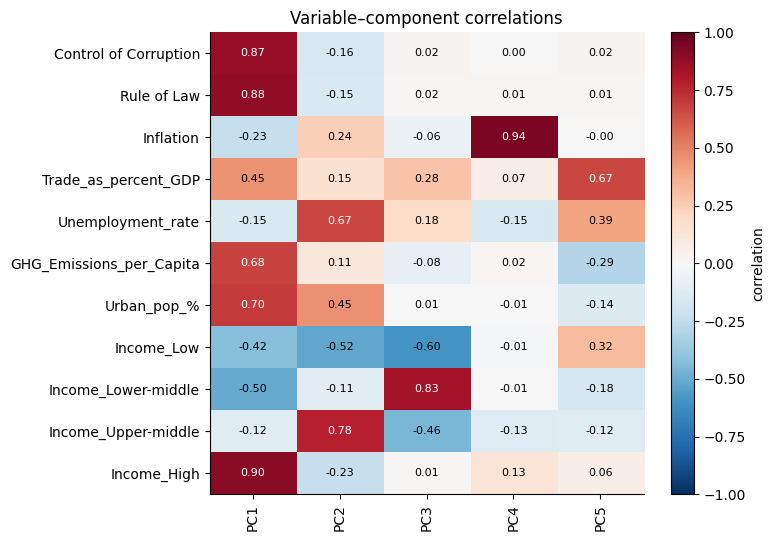

In [ ]:
# Variable-component correlation heatmap, all five components
fig, ax = plt.subplots(figsize=(7, 6))
heatmap(corr, ax)
ax.set_title("Variable–component correlations")
plt.show()

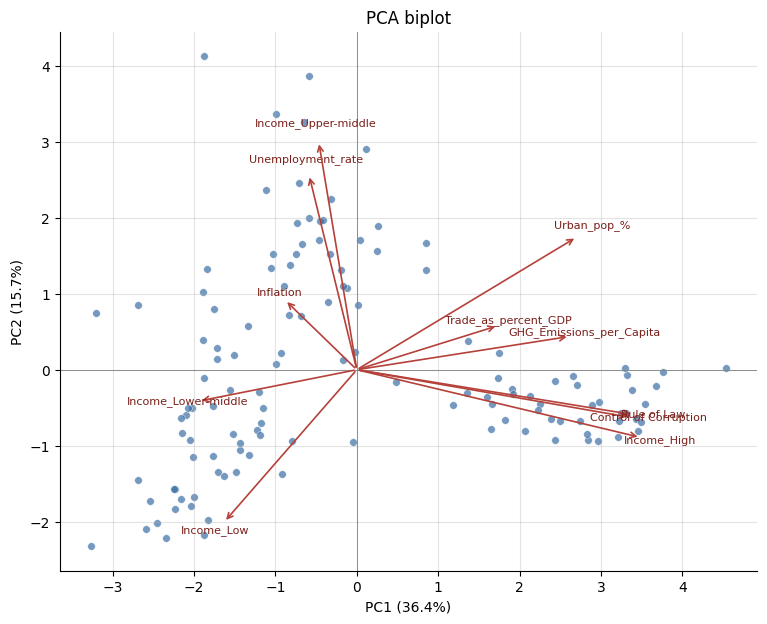

In [ ]:
# biplot: arrows are rescaled so they are visible against the score cloud.
def biplot(ax, scores, corr, color="#3b6ea5", c=None, cmap=None):
    k = 0.85 * np.abs(scores[:, :2]).max()
    ax.scatter(scores[:, 0], scores[:, 1], s=30, alpha=.7, c=c if c is not None else color,
            cmap=cmap, edgecolor="white", linewidth=.4)
    for var, (x, y) in corr[["PC1", "PC2"]].iterrows():
        ax.annotate("", xy=(x * k, y * k), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="#b5413a", lw=1.2))
        ax.text(x * k * 1.07, y * k * 1.07, var, fontsize=8, color="#7a1f1a", ha="center")
    ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6)
    ax.set_xlabel(f"PC1 ({evr.explained.iloc[0]:.1%})"); ax.set_ylabel(f"PC2 ({evr.explained.iloc[1]:.1%})")

fig, ax = plt.subplots(figsize=(9, 7))
biplot(ax, scores, corr)
ax.set_title("PCA biplot")
plt.show()

### Task 2 – Interpretation

**How much the model captures.** PC1 holds 36.4% of the variance and PC2 another 15.7%, so the 2D plots show about 52% of the information. Five components reach 80.7%. The two-dimensional pictures are useful but are a partial view.

**PC1 is a development / institutions axis.** Control of Corruption (0.87), Rule of Law (0.88), the High-income dummy (0.90), urban share (0.70) and emissions per capita (0.68) all load strongly positive. The Low and Lower-middle dummies load negative. Moving right means richer, better-governed, more urban and more emissions-intensive.

**PC2 is about the middle of the income range and the labour market.** Unemployment (0.67) and the Upper-middle dummy (0.78) load positive, the Low-income dummy negative (–0.52). Countries high on PC2 are upper-middle-income economies with comparatively high unemployment.

**Later components.** PC3 separates the Lower-middle dummy (0.83) from the Low one (–0.60), so it mostly splits the two poorest income bands. PC4 is almost entirely inflation (0.94) and PC5 is trade openness (0.67) with some unemployment.

**Relationships I found worth noting.**
- Corruption control and rule of law are almost the same variable (both ≈0.87 on PC1, pointing the same way in the circle).
- Inflation is nearly uncorrelated with everything else. It needs its own component and is invisible in the PC1/PC2 plane. Its spread is also driven by a few extreme values, which matters again in Task 6.
- Income enters four times (four dummies out of eleven columns), so PC1 leans toward income more than a plain eight-variable PCA would. That is a consequence of the task design and I am keeping it.

**Clusters.** The scatter shows a continuous gradient from left to right, not clean islands. There is a visible group of rich countries on the right, a dense group of low-income countries on the left, and an overlapping middle. Task 3 puts boundaries on that gradient.

## Task 3 – Hierarchical clustering (Ward, 4 clusters)

Ward linkage on the first two principal components, cut with `maxclust` at 4. Ward minimizes within-cluster variance and works on Euclidean distances, which is what PCA scores give us.

cluster sizes: {1: 41, 2: 32, 3: 14, 4: 41}


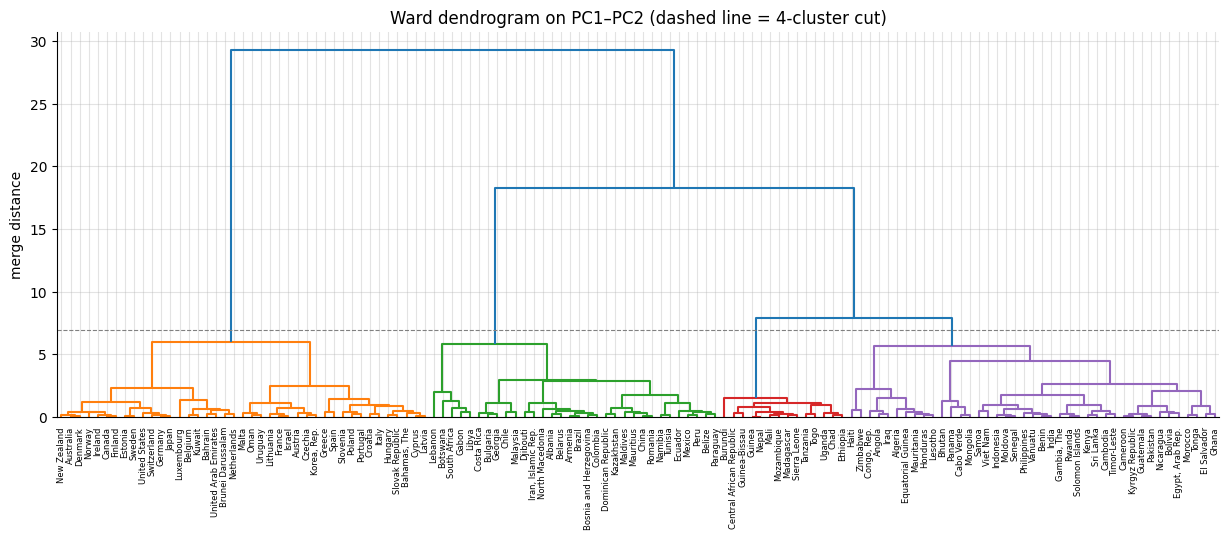

In [9]:
pc12 = scores[:, :2]
Z = linkage(pc12, method="ward")
labels = fcluster(Z, t=4, criterion="maxclust")

print("cluster sizes:", {int(k): int(n) for k, n in zip(*np.unique(labels, return_counts=True))})
cut = (Z[-4, 2] + Z[-3, 2]) / 2     # any height between the 3rd- and 4th-last merge gives 4 clusters

fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(Z, labels=X.index.to_list(), leaf_font_size=6, color_threshold=cut, ax=ax)
ax.axhline(cut, color="grey", ls="--", lw=.8)
ax.set_title("Ward dendrogram on PC1–PC2 (dashed line = 4-cluster cut)")
ax.set_ylabel("merge distance")
plt.show()

## Task 4 – Clustered PCA plot

Cluster labels are added to the PCA results. The names below come from the cluster profiles in Task 5 (income mix and means), so you would read them as descriptions, not as inputs to the model.

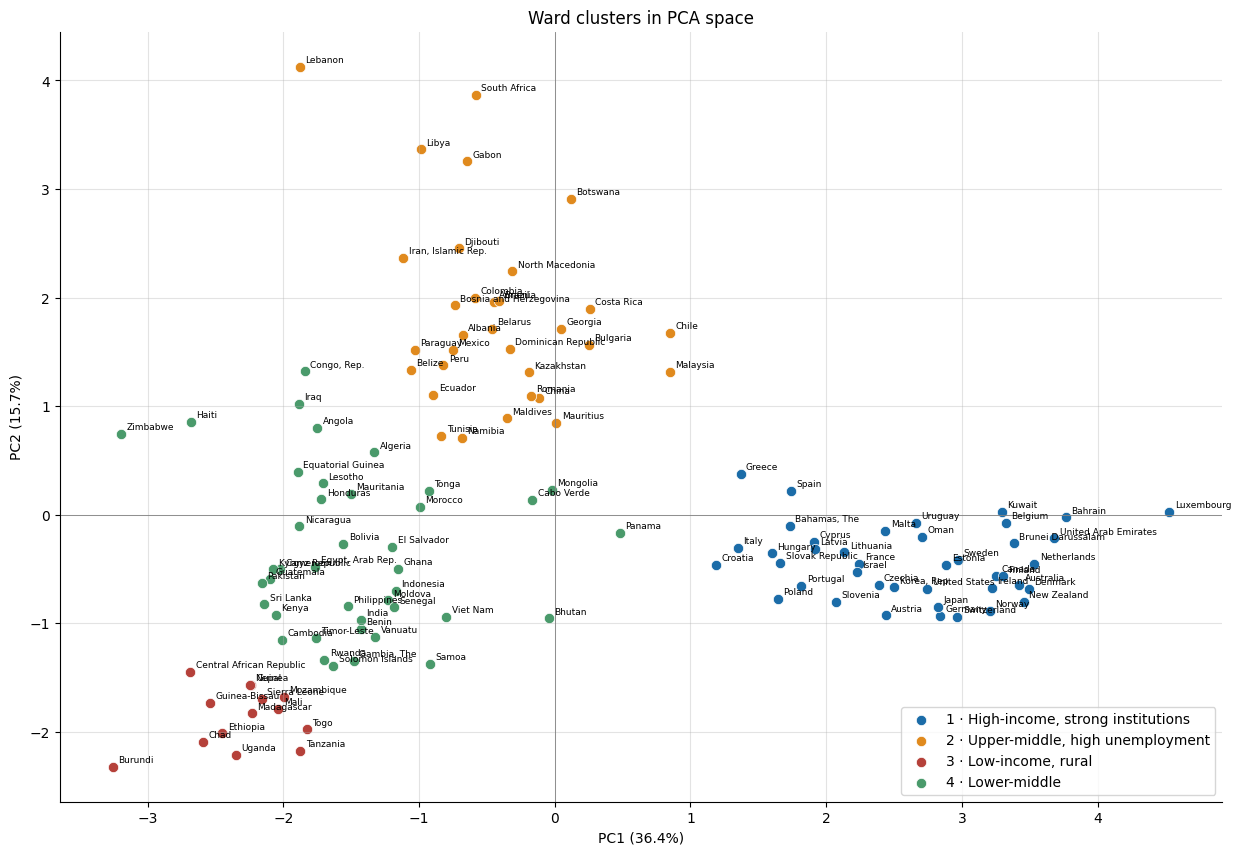

In [ ]:
res = pd.DataFrame(pc12, index=X.index, columns=["PC1", "PC2"])
res["cluster"] = labels

cluster_names = {1: "1 · High-income, strong institutions",
                2: "2 · Upper-middle, high unemployment",
                3: "3 · Low-income, rural",
                4: "4 · Lower-middle"}
palette = {1: "#1b6ca8", 2: "#e08a1e", 3: "#b5413a", 4: "#4a9a6b"}

fig, ax = plt.subplots(figsize=(15, 10))
for k, g in res.groupby("cluster"):
    ax.scatter(g.PC1, g.PC2, s=55, color=palette[k], label=cluster_names[k],
            edgecolor="white", linewidth=.5)
    for name, r in g.iterrows():
        ax.text(r.PC1 + .04, r.PC2 + .04, name, fontsize=6.5)
ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6)
ax.set_xlabel(f"PC1 ({evr.explained.iloc[0]:.1%})"); ax.set_ylabel(f"PC2 ({evr.explained.iloc[1]:.1%})")
ax.set_title("Ward clusters in PCA space")
ax.legend(loc="lower right")
plt.show()

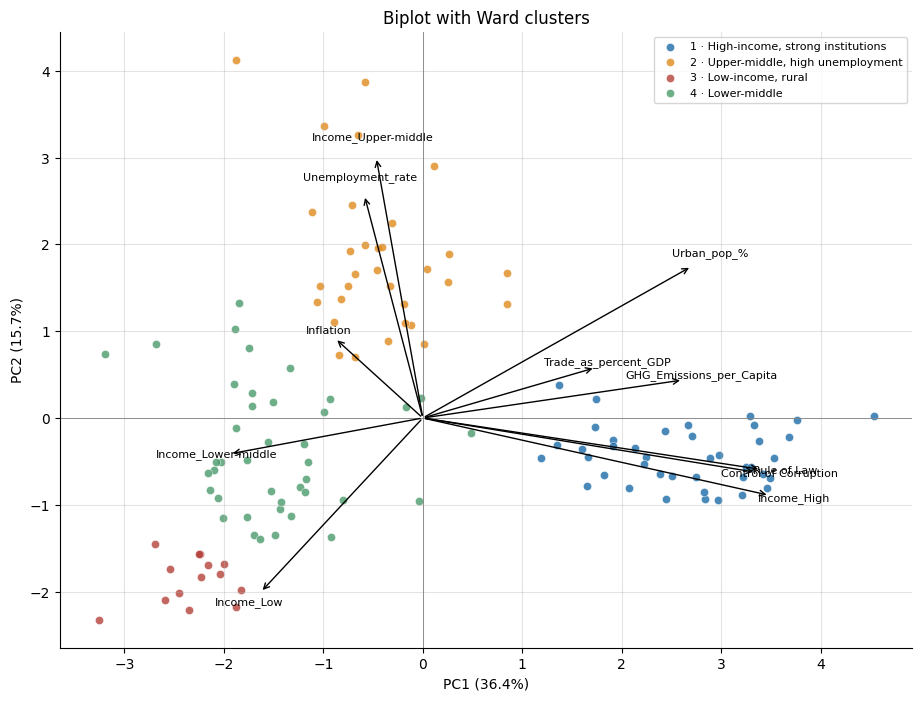

In [ ]:
# biplot with cluster colours
fig, ax = plt.subplots(figsize=(11, 8))
k = 0.85 * np.abs(pc12).max()
for g_id, g in res.groupby("cluster"):
    ax.scatter(g.PC1, g.PC2, s=35, color=palette[g_id], label=cluster_names[g_id],
        edgecolor="white", linewidth=.4, alpha=.8)
for var, (x, y) in corr[["PC1", "PC2"]].iterrows():
    ax.annotate("", xy=(x * k, y * k), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="black", lw=1))
    ax.text(x * k * 1.07, y * k * 1.07, var, fontsize=8, ha="center")
ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6)
ax.set_xlabel(f"PC1 ({evr.explained.iloc[0]:.1%})"); ax.set_ylabel(f"PC2 ({evr.explained.iloc[1]:.1%})")
ax.set_title("Biplot with Ward clusters"); ax.legend(loc="upper right", fontsize=8)
plt.show()

In [12]:
# quick membership check by income band
pd.crosstab(pd.Series(labels, index=wdi.index, name="Ward cluster"), wdi["Income_Level"])

Income_Level,Low,Lower-middle,Upper-middle,High
Ward cluster,,,,
1,0,0,0,41
2,0,3,29,0
3,14,0,0,0
4,2,37,1,1


### Task 4 – Findings

- The clusters line up with income band. Cluster 1 comprizes almost entirely High-income countries, Cluster 3 is almost entirely Low-income, Cluster 2 is dominated by Upper-middle-income countries and Cluster 4 by Lower-middle-income countries (see the crosstab above).
- Cluster 1 sits far right along the governance and emissions arrows. Cluster 3 sits at the far left, opposite those arrows.
- Clusters 2 and 4 are neighbors and their boundary is soft. The few countries that do not match their cluster's income band are the border cases: Panama (High-income, placed in cluster 4), Tonga (Upper-middle, Cluster 4), Gambia and Rwanda (Low-income, cluster 4), and Djibouti, Namibia and Tunisia (Lower-middle, cluster 2). I would not over-interpret those assignments.
- Cluster 2 pulled up the unemployment arrow, which is what separates it from Cluster 4.
- Because the clustering used only PC1–PC2 (about 52% of the variance), anything carried by later components, especially inflation, did not influence these groups.

## Task 5 – Radar plot of cluster profiles

Same standardized matrix as the PCA (11 features), averaged within each Ward cluster. A value of 0 is the global mean and units are standard deviations.

In [13]:
Xs_df = pd.DataFrame(Xs, index=X.index, columns=X.columns)
prof_h = Xs_df.groupby(labels).mean()
prof_h.index = [cluster_names[i] for i in prof_h.index]
prof_h.T.round(2)

,"1 · High-income, strong institutions","2 · Upper-middle, high unemployment","3 · Low-income, rural",4 · Lower-middle
Control of Corruption,1.11,-0.33,-0.91,-0.54
Rule of Law,1.13,-0.30,-1.01,-0.55
Inflation,-0.20,0.16,-0.01,0.08
Trade_as_percent_GDP,0.54,0.04,-0.69,-0.34
Unemployment_rate,-0.33,0.73,-0.61,-0.03
GHG_Emissions_per_Capita,0.82,-0.05,-0.75,-0.52
Urban_pop_%,0.80,0.34,-1.30,-0.63
Income_Low,-0.38,-0.38,2.65,-0.23
Income_Lower-middle,-0.67,-0.47,-0.67,1.27
Income_Upper-middle,-0.55,1.59,-0.55,-0.50


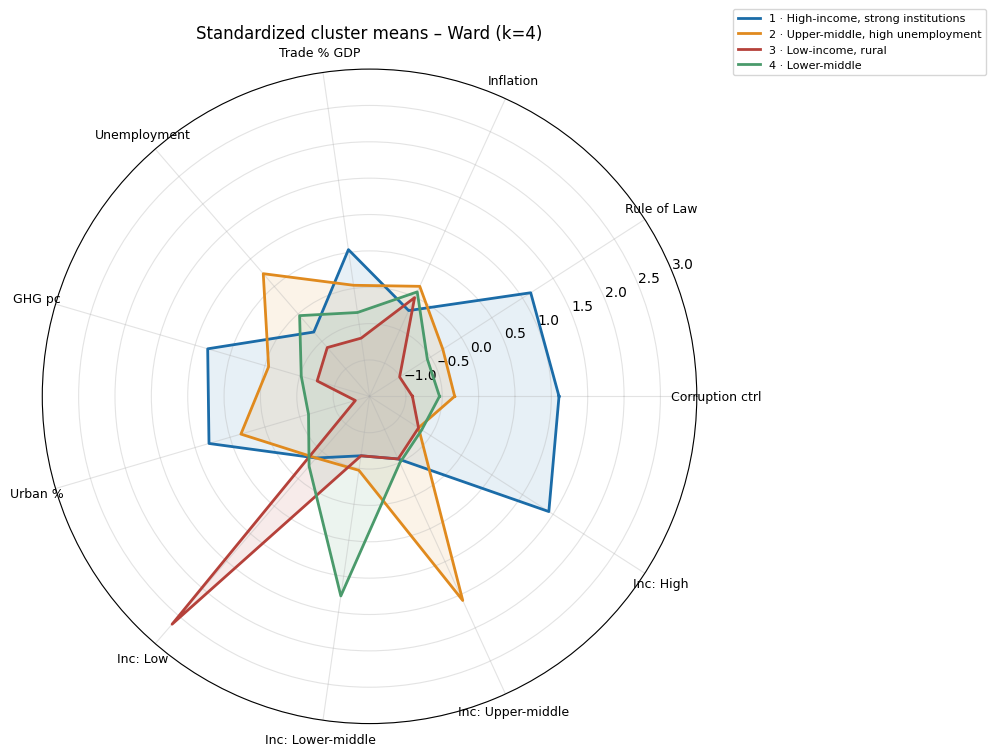

In [ ]:
def radar(profile, colors, title, ylim=(-1.5, 3.0)):
    cats = [c.replace("Control of Corruption", "Corruption ctrl").replace("Trade_as_percent_GDP", "Trade % GDP")
            .replace("Unemployment_rate", "Unemployment").replace("GHG_Emissions_per_Capita", "GHG pc")
            .replace("Urban_pop_%", "Urban %").replace("GNI_per_capita", "GNI pc").replace("Income_", "Inc: ")
            for c in profile.columns]
    ang = np.linspace(0, 2 * np.pi, len(cats), endpoint=False).tolist()
    ang += ang[:1]
    fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw=dict(polar=True))
    for (name, row), col in zip(profile.iterrows(), colors):
        vals = row.to_list() + row.to_list()[:1]
        ax.plot(ang, vals, color=col, lw=2, label=name)
        ax.fill(ang, vals, color=col, alpha=.10)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(cats, fontsize=9)
    ax.set_ylim(*ylim); ax.set_title(title, pad=22)
    ax.legend(loc="upper right", bbox_to_anchor=(1.45, 1.1), fontsize=8)
    plt.show()

radar(prof_h, [palette[i] for i in range(1, 5)], "Standardized cluster means – Ward (k=4)")

### Task 5 – Observations

- **Cluster 1 (high-income):** corruption control +1.11 SD and rule of law +1.13 SD, plus above-average emissions (+0.82), urbanization (+0.80) and trade (+0.54). Unemployment is a little below average.
- **Cluster 2 (upper-middle):** the standout is unemployment at +0.73 SD. Institutions are slightly below average and urbanization slightly above, so this is a middle profile with labour-market stress.
- **Cluster 3 (low-income):** the most extreme cluster. Low-income dummy at +2.65 SD, urbanization at –1.30, and corruption control, rule of law, emissions and trade all clearly negative. Unemployment is *below* average (–0.61), which I would not read as good news. Headline unemployment counts open job-seeking and misses informal and subsistence work, so it tends to look low in the poorest economies.
- **Cluster 4 (lower-middle):** moderately negative on almost everything (institutions about –0.55, urbanization –0.63), sitting between clusters 2 and 3.
- **Inflation is almost flat across clusters** (between –0.20 and +0.16 SD), consistent with the PCA finding that it lives on a different component. Ward clusters built from PC1–PC2 simply do not see it.

## Task 6 – K-means on the original data

K-means uses `merged_data.csv` as given (eight indicators including GNI per capita, no dummies, no PCA). I still standardize, since K-means is distance-based and GNI in dollars would otherwise drown out everything else.

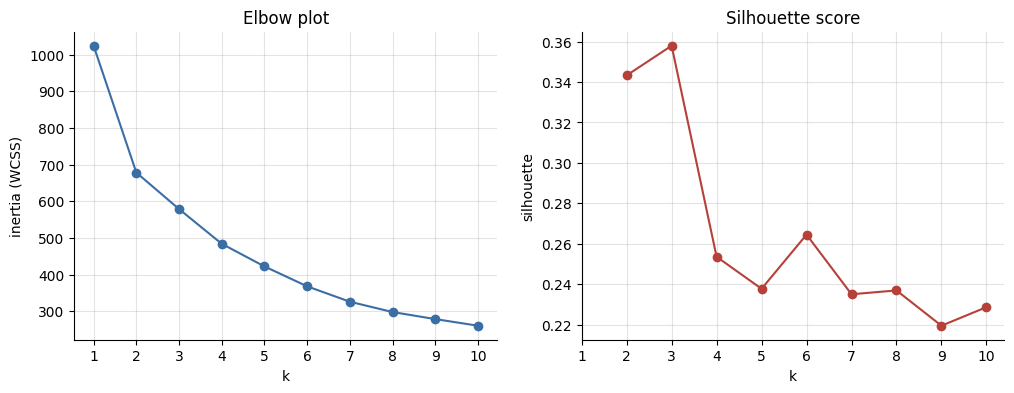

,inertia,drop vs previous k,silhouette
k,,,
1,1024.000,NaN,NaN
2,678.087,345.913,0.343
3,578.594,99.492,0.358
4,483.885,94.710,0.254
5,422.174,61.711,0.238
6,367.885,54.289,0.264
7,325.915,41.969,0.235
8,297.740,28.175,0.237
9,278.530,19.210,0.219


In [ ]:
raw_vars = wdi.drop(columns="Income_Level")
Xr = StandardScaler().fit_transform(raw_vars)
Xr_df = pd.DataFrame(Xr, index=raw_vars.index, columns=raw_vars.columns)

ks = range(1, 11)
inertia, sil = [], [np.nan]
for k in ks:
    km = KMeans(n_clusters=k, n_init=100, random_state=SEED).fit(Xr)
    inertia.append(km.inertia_)
    if k > 1:
        sil.append(silhouette_score(Xr, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, "o-", color="#3b6ea5"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia (WCSS)")
axes[0].set_title("Elbow plot")
axes[1].plot(list(ks), sil, "o-", color="#b5413a"); axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette")
axes[1].set_title("Silhouette score")
for a in axes: a.set_xticks(list(ks))
plt.show()

pd.DataFrame({"inertia": inertia, "drop vs previous k": np.r_[np.nan, -np.diff(inertia)], "silhouette": sil},
            index=pd.Index(ks, name="k")).round(3)

### Choice of K

The elbow is not sharp. The big gain is k=1 to k=2 (inertia 1024 → 678). Then the drops hold at roughly 100 for k=3 and k=4 and fall to about 60 and below after that, so the bend is around **k=4**. Silhouette peaks at k=3 (0.36), but I do not trust that number, for the reason below.

**A warning about outliers!** Once K-means is given enough restarts (`n_init=100`), the best k=3 solution spends a whole cluster on two countries, Lebanon and Zimbabwe, whose inflation (171% and 105%) is about 7 standard deviations above the mean. With only 10 restarts I got a different k=3 solution (inertia 580.5 vs 578.6), and at k=4 I saw several near-tied solutions (inertia 483.9 to 486.7) depending on the seed, so the outcome depends on initialization. I use 100 restarts because, for k=2 through 5, that gave the same best solution under every one of the 10 seeds I tried. The high k=3 silhouette comes largely from that tiny, well-separated cluster. The same two countries stay isolated at k=4 and k=5.

So I pick **k=4**: one cluster is the Lebanon/Zimbabwe outlier pair, and the other three are substantive groups. At k=3 only two substantive groups would remain. The code below fixes the seed and uses many restarts so the result is reproducible.

In [16]:
km = KMeans(n_clusters=4, n_init=100, random_state=SEED).fit(Xr)
sizes = np.bincount(km.labels_)

# relabel clusters by size (largest first) so the labels are readable
order_k = np.argsort(-sizes)
remap = {old: new for new, old in enumerate(order_k)}
km_labels = np.array([remap[l] for l in km.labels_])
sizes = np.bincount(km_labels)

print("cluster sizes:", sizes)
print("smallest cluster:", Xr_df.index[km_labels == sizes.argmin()].to_list())

prof_k = Xr_df.groupby(km_labels).mean()
prof_k.index = [f"K{i} (n={n})" for i, n in enumerate(sizes)]
prof_k.T.round(2)

cluster sizes: [51 41 34  2]
smallest cluster: ['Lebanon', 'Zimbabwe']


,K0 (n=51),K1 (n=41),K2 (n=34),K3 (n=2)
Control of Corruption,-0.54,1.13,-0.48,-1.20
Rule of Law,-0.54,1.15,-0.50,-1.25
GNI_per_capita,-0.59,1.14,-0.45,-0.58
Inflation,-0.06,-0.21,-0.06,6.97
Trade_as_percent_GDP,-0.46,0.53,0.05,-0.17
Unemployment_rate,-0.51,-0.36,1.15,0.71
GHG_Emissions_per_Capita,-0.55,0.83,-0.15,-0.55
Urban_pop_%,-0.88,0.83,0.32,-0.07


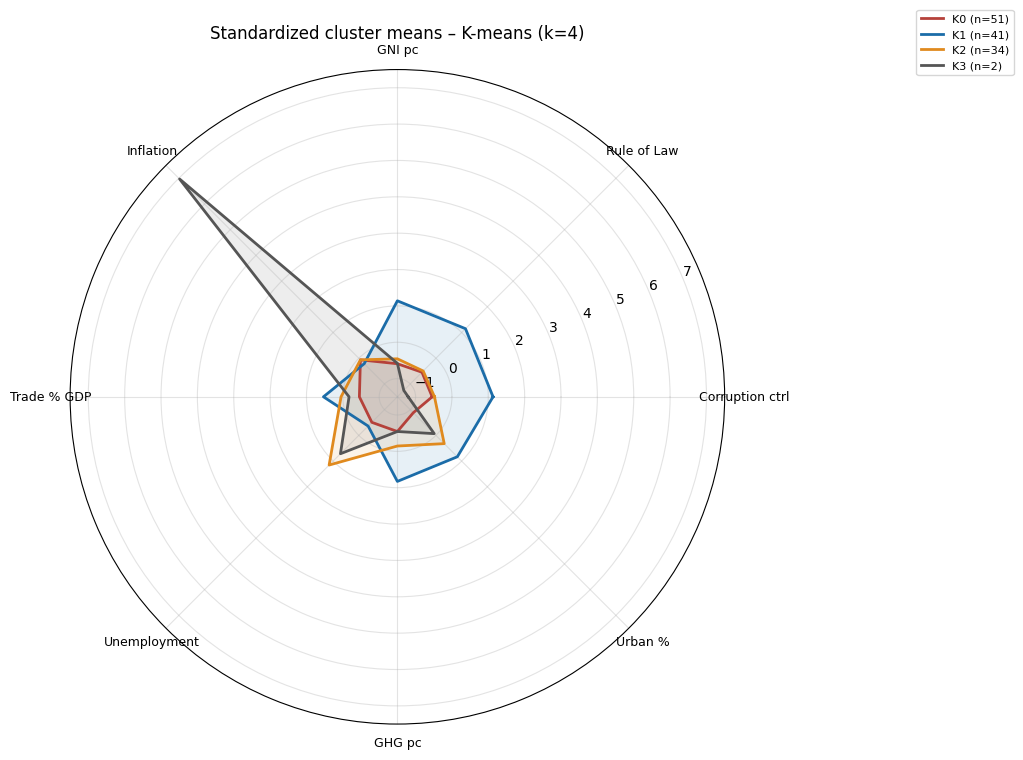

In [17]:
# full scale: the outlier pair's inflation (+7 SD) dominates the axis
radar(prof_k, ["#b5413a", "#1b6ca8", "#e08a1e", "#555555"], "Standardized cluster means – K-means (k=4)", ylim=(-1.5, 7.5))

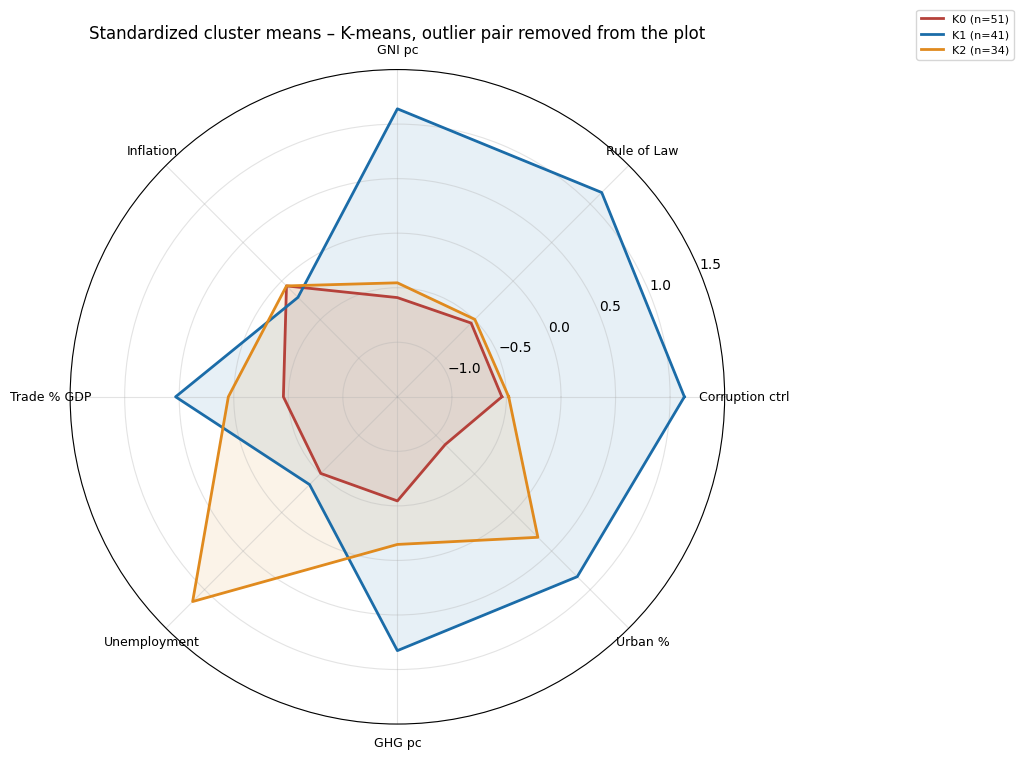

In [18]:
# zoomed: the three substantive clusters only, comparable to the Task 5 radar
radar(prof_k.iloc[[0, 1, 2]], ["#b5413a", "#1b6ca8", "#e08a1e"],
      "Standardized cluster means – K-means, outlier pair removed from the plot", ylim=(-1.5, 1.5))

In [19]:
# agreement with the Task 5 clusters
print("Adjusted Rand Index (Ward k=4 vs K-means k=4):", round(adjusted_rand_score(labels, km_labels), 3))
pd.crosstab(pd.Series(labels, index=raw_vars.index, name="Ward cluster"),
            pd.Series(km_labels, index=raw_vars.index, name="K-means cluster"))

Adjusted Rand Index (Ward k=4 vs K-means k=4): 0.438


K-means cluster,0,1,2,3
Ward cluster,,,,
1,0,39,2,0
2,10,2,19,1
3,14,0,0,0
4,27,0,13,1


In [20]:
# robustness: same K-means after log-transforming the two heavily skewed variables
logged = raw_vars.assign(Inflation=np.log(raw_vars["Inflation"]), GNI_per_capita=np.log(raw_vars["GNI_per_capita"]))
Xl = StandardScaler().fit_transform(logged)
for k in (3, 4):
    kl = KMeans(n_clusters=k, n_init=100, random_state=SEED).fit(Xl)
    print(f"log version, k={k}: sizes {np.bincount(kl.labels_)}, silhouette {silhouette_score(Xl, kl.labels_):.3f}")

log version, k=3: sizes [41 47 40], silhouette 0.231
log version, k=4: sizes [45 39  8 36], silhouette 0.223


### Task 6 – Comparison with Task 5

- **K1 (n=41, high-income)** is essentially Ward cluster 1 (39 of its 41 countries are shared): governance about +1.1 SD, above-average emissions, urbanization and trade.
- **K2 (n=34)** has unemployment at +1.15 SD and is slightly urban (+0.32). It is closest to Ward cluster 2, the labour-market-stress group, but it also pulls in 13 of Ward's lower-middle cluster, so it is broader.
- **K0 (n=51)** is weak on every dimension and especially rural (urbanization –0.88). It absorbs all of Ward's low-income cluster plus most of the lower-middle cluster, and 10 countries from Ward cluster 2.
- **K3 (Lebanon, Zimbabwe)** has no counterpart in Task 5, because Ward on PC1–PC2 never sees inflation.
- Overall agreement is moderate (Adjusted Rand Index about 0.44). The top group is stable under both methods. The disagreement is in the middle and bottom, where Ward uses income dummies to separate low from lower-middle and K-means, working with the raw GNI value and all eight indicators, does not.
- The two methods are really answering different questions. Ward-on-PCA gives a clean income-development ladder and ignores inflation. K-means keeps inflation, which is why it spends a cluster on two crisis economies.
- The log-transform check shows how much of this is an outlier effect. After logging inflation and GNI, k=3 returns three balanced clusters (sizes around 41/47/40) and no tiny outlier cluster. If I were building this for use I would take that version, but for this assignment the instructions say to use the original data, so I report that first and treat the log version as a sanity check.

# Part 2 – FICO Loans: EDA and Linear Regression

In [21]:
fico = pd.read_csv(find_file("ficoscores.csv", "fcoscores.csv"))
print(fico.shape)
print(fico.isna().sum()[lambda s: s > 0])
fico.dtypes

(9513, 14)
meets_credit_criteria    2
dtype: int64


meets_credit_criteria    float64
loan_purpose              object
interest_rate            float64
monthly_installment      float64
log_annual_income        float64
debt_to_income           float64
fico_score                 int64
credit_history_days      float64
revolving_balance        float64
revolving_utilization    float64
recent_inquiries         float64
delinquencies_2yrs       float64
public_records           float64
loan_defaulted             int64
dtype: object

## Task 7 – Exploratory data analysis

### Raw histograms: interest rate and FICO score

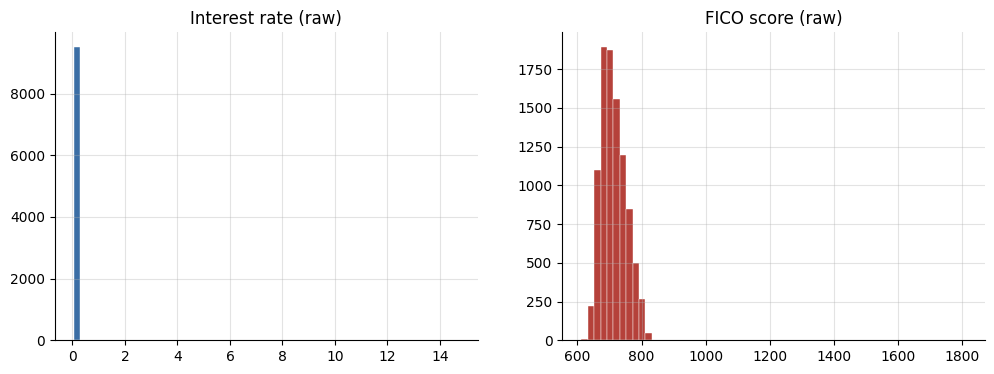

     interest_rate  fico_score        loan_purpose
170          14.70         632           all_other
799          13.25         687  debt_consolidation
     interest_rate  fico_score        loan_purpose
110         0.1059        1712         credit_card
174         0.0712        1812    home_improvement
565         0.1703        1662  debt_consolidation


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(fico["interest_rate"], bins=60, color="#3b6ea5", edgecolor="white", linewidth=.3)
axes[0].set_title("Interest rate (raw)")
axes[1].hist(fico["fico_score"], bins=60, color="#b5413a", edgecolor="white", linewidth=.3)
axes[1].set_title("FICO score (raw)")
plt.show()

print(fico.loc[fico["interest_rate"] > 1, ["interest_rate", "fico_score", "loan_purpose"]])
print(fico.loc[fico["fico_score"] > 850, ["interest_rate", "fico_score", "loan_purpose"]])

**Something is off in both plots.**
- Interest rate is stored as a fraction (typical values 0.06–0.22), but two rows read 13.25 and 14.70. Those were almost certainly typed in as percentages. They stretch the x-axis so the real distribution is squeezed into a thin sliver on the left.
- FICO scores are bounded between 300 and 850, yet three rows read 1,662, 1,712 and 1,812. These are impossible values (likely typos, perhaps a stray leading "1"), not just high ones.

Both sets of errors sit above the 99th percentile, so the trimming rule below removes them. In real work I would first try to correct them (13.25 → 0.1325) rather than delete, but the task specifies the trimming rule, so I follow it and note the choice.

### Summary table: IQR and 99th percentile

In [23]:
num_cols = fico.select_dtypes("number").columns.to_list()

q = fico[num_cols].quantile([.25, .75, .99]).T
q.columns = ["Q1", "Q3", "P99"]
q["IQR"] = q["Q3"] - q["Q1"]
q["max"] = fico[num_cols].max()
q["n above P99"] = (fico[num_cols] > q["P99"]).sum()
q[["Q1", "Q3", "IQR", "P99", "max", "n above P99"]].round(3)

,Q1,Q3,IQR,P99,max,n above P99
meets_credit_criteria,1.000,1.000,0.000,1.000,1.000,0
interest_rate,0.104,0.141,0.037,0.189,14.700,95
monthly_installment,164.020,435.360,271.340,870.390,940.140,94
log_annual_income,10.566,11.290,0.724,12.471,14.528,96
debt_to_income,7.230,18.000,10.770,26.249,29.960,96
fico_score,682.000,737.000,55.000,802.000,1812.000,92
credit_history_days,2820.000,5730.042,2910.042,12930.037,17639.958,96
revolving_balance,3273.000,18367.000,15094.000,156655.280,1207359.000,96
revolving_utilization,22.700,71.000,48.300,99.000,670.000,87
recent_inquiries,0.000,2.000,2.000,9.000,33.000,94


### Trimming at the 99th percentile

For every numeric variable, thresholds come from the *original* data and any row above the threshold in **any** variable is dropped. Using fixed thresholds matters: if I recomputed the percentile after each filter, the data would shrink further on every pass and I would not land on the expected row count. The two rows with a missing `meets_credit_criteria` also drop out here, because a comparison with NaN is False.

In [24]:
p99 = fico[num_cols].quantile(.99)
keep = (fico[num_cols] <= p99).all(axis=1)      # NaN fails the test, so missing rows go too
df = fico[keep].reset_index(drop=True)

print("rows before:", len(fico), "| after:", len(df), f"| dropped {1 - len(df)/len(fico):.1%}")
assert df.shape == (8661, 14), df.shape
df.describe().T.round(3)

rows before: 9513 | after: 8661 | dropped 9.0%


,count,mean,std,min,25%,50%,75%,max
meets_credit_criteria,8661.0,0.838,0.368,0.000,1.000,1.000,1.000,1.000
interest_rate,8661.0,0.121,0.025,0.060,0.102,0.122,0.138,0.189
monthly_installment,8661.0,312.583,197.772,15.670,163.680,267.730,419.840,870.390
log_annual_income,8661.0,10.898,0.570,7.548,10.545,10.915,11.277,12.468
debt_to_income,8661.0,12.558,6.699,0.000,7.290,12.700,17.860,26.240
fico_score,8661.0,711.306,36.520,612.000,682.000,707.000,737.000,802.000
credit_history_days,8661.0,4403.112,2274.166,180.042,2760.042,4079.000,5580.042,12930.000
revolving_balance,8661.0,14279.602,18678.274,0.000,3292.000,8545.000,17588.000,155946.000
revolving_utilization,8661.0,46.447,28.339,0.000,23.100,46.000,70.000,99.000
recent_inquiries,8661.0,1.415,1.705,0.000,0.000,1.000,2.000,9.000


Result: 8,661 rows × 14 columns, matching the target. Trimming 1% per variable across 13 numeric columns removes about 9% of rows in total. That is the price of this blunt rule, and a few legitimate large revolving balances or long credit histories are lost along with the data-entry errors.

### Interest rate by loan purpose

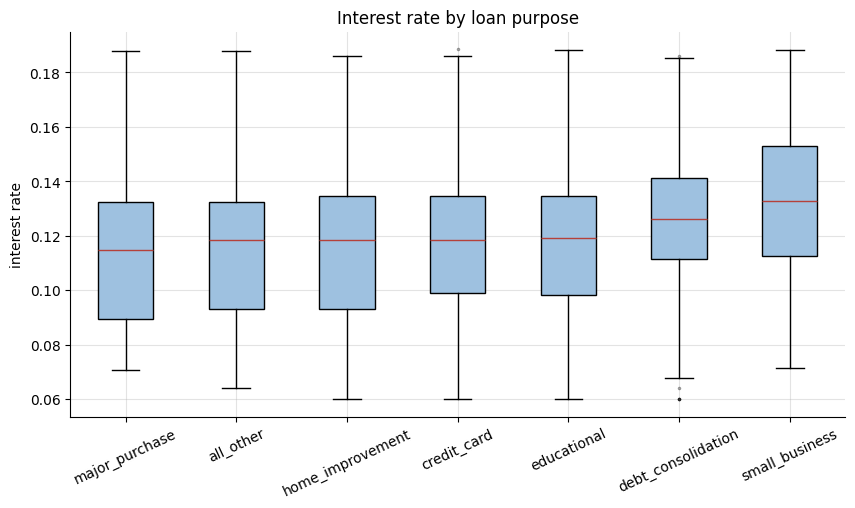

,count,median,mean
loan_purpose,,,
major_purchase,392,0.1148,0.1132
all_other,2085,0.1183,0.1155
home_improvement,554,0.1183,0.1161
credit_card,1151,0.1183,0.1180
educational,315,0.1191,0.1188
debt_consolidation,3662,0.1261,0.1249
small_business,502,0.1326,0.1328


In [ ]:
order = df.groupby("loan_purpose")["interest_rate"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5))
box_data = [df.loc[df["loan_purpose"] == p, "interest_rate"] for p in order]
ax.boxplot(box_data, patch_artist=True, boxprops=dict(facecolor="#9ec1e0"),
        medianprops=dict(color="#b5413a"), flierprops=dict(marker=".", markersize=3, alpha=.4))
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
ax.set_xlabel(""); ax.set_ylabel("interest rate"); ax.tick_params(axis="x", rotation=25)
ax.set_title("Interest rate by loan purpose")
plt.show()
df.groupby("loan_purpose")["interest_rate"].agg(["count", "median", "mean"]).round(4).loc[order]

Medians sit in a narrow band (about 11.5%–13.3%) and the boxes overlap heavily, so purpose by itself separates rates only slightly. Small business loans stand out as the most expensive (median about 13.3%) and debt consolidation is next. Major purchase is the cheapest. Purpose will matter at the margin, not as the main driver.

### Correlation heatmap

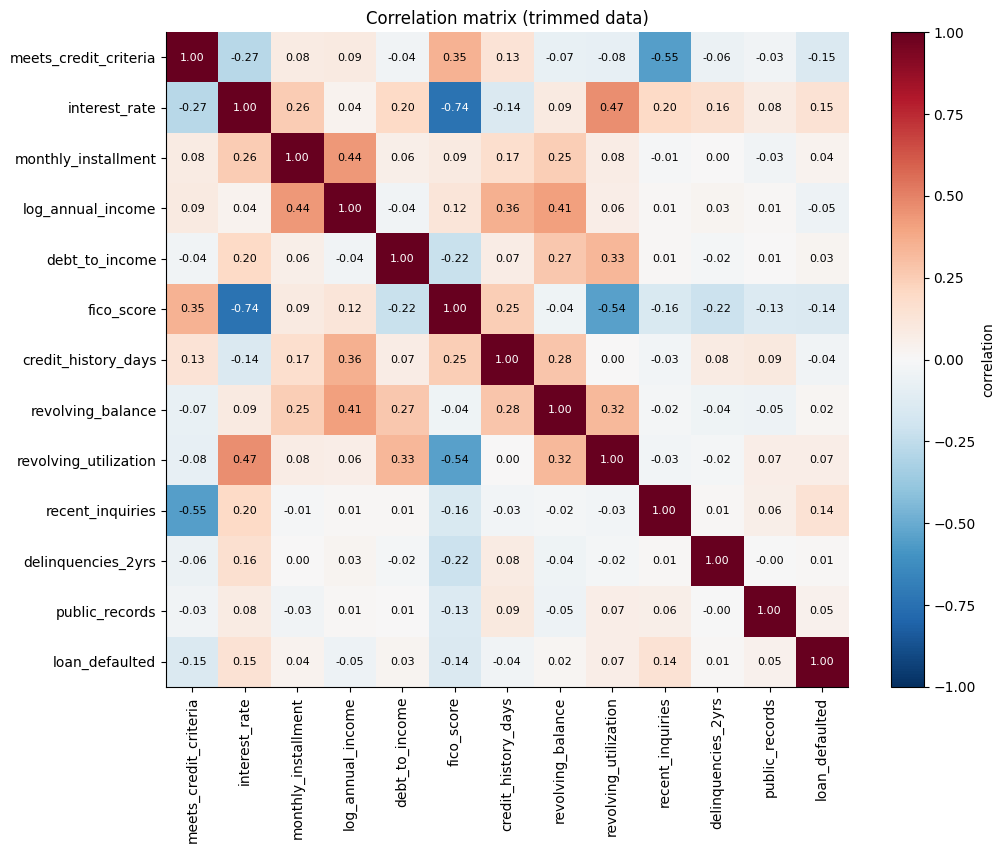

In [26]:
fig, ax = plt.subplots(figsize=(11, 8.5))
heatmap(df[num_cols].corr(), ax)
ax.set_title("Correlation matrix (trimmed data)")
plt.show()

- **FICO is the dominant correlate of interest rate (–0.74).** Better credit, lower rate, as expected.
- **Revolving utilization is next (+0.47)**, and it is itself correlated with FICO (–0.54), so some of its effect overlaps with FICO's.
- Debt-to-income (+0.20), recent inquiries (+0.20) and delinquencies (+0.16) have modest positive links to the rate.
- **Log income and monthly installment are correlated (0.44)** and installment has a +0.26 link with rate. I would be careful with installment: it is computed from loan amount, term *and rate*, so it is partly a function of the thing I want to predict.
- `meets_credit_criteria` correlates strongly with recent inquiries (–0.55), which suggests it is a rule-based flag made from other fields.
- Loan default has only weak correlations with anything (largest ±0.15), so it will be hard to predict from these features.

### Histograms of all numeric variables

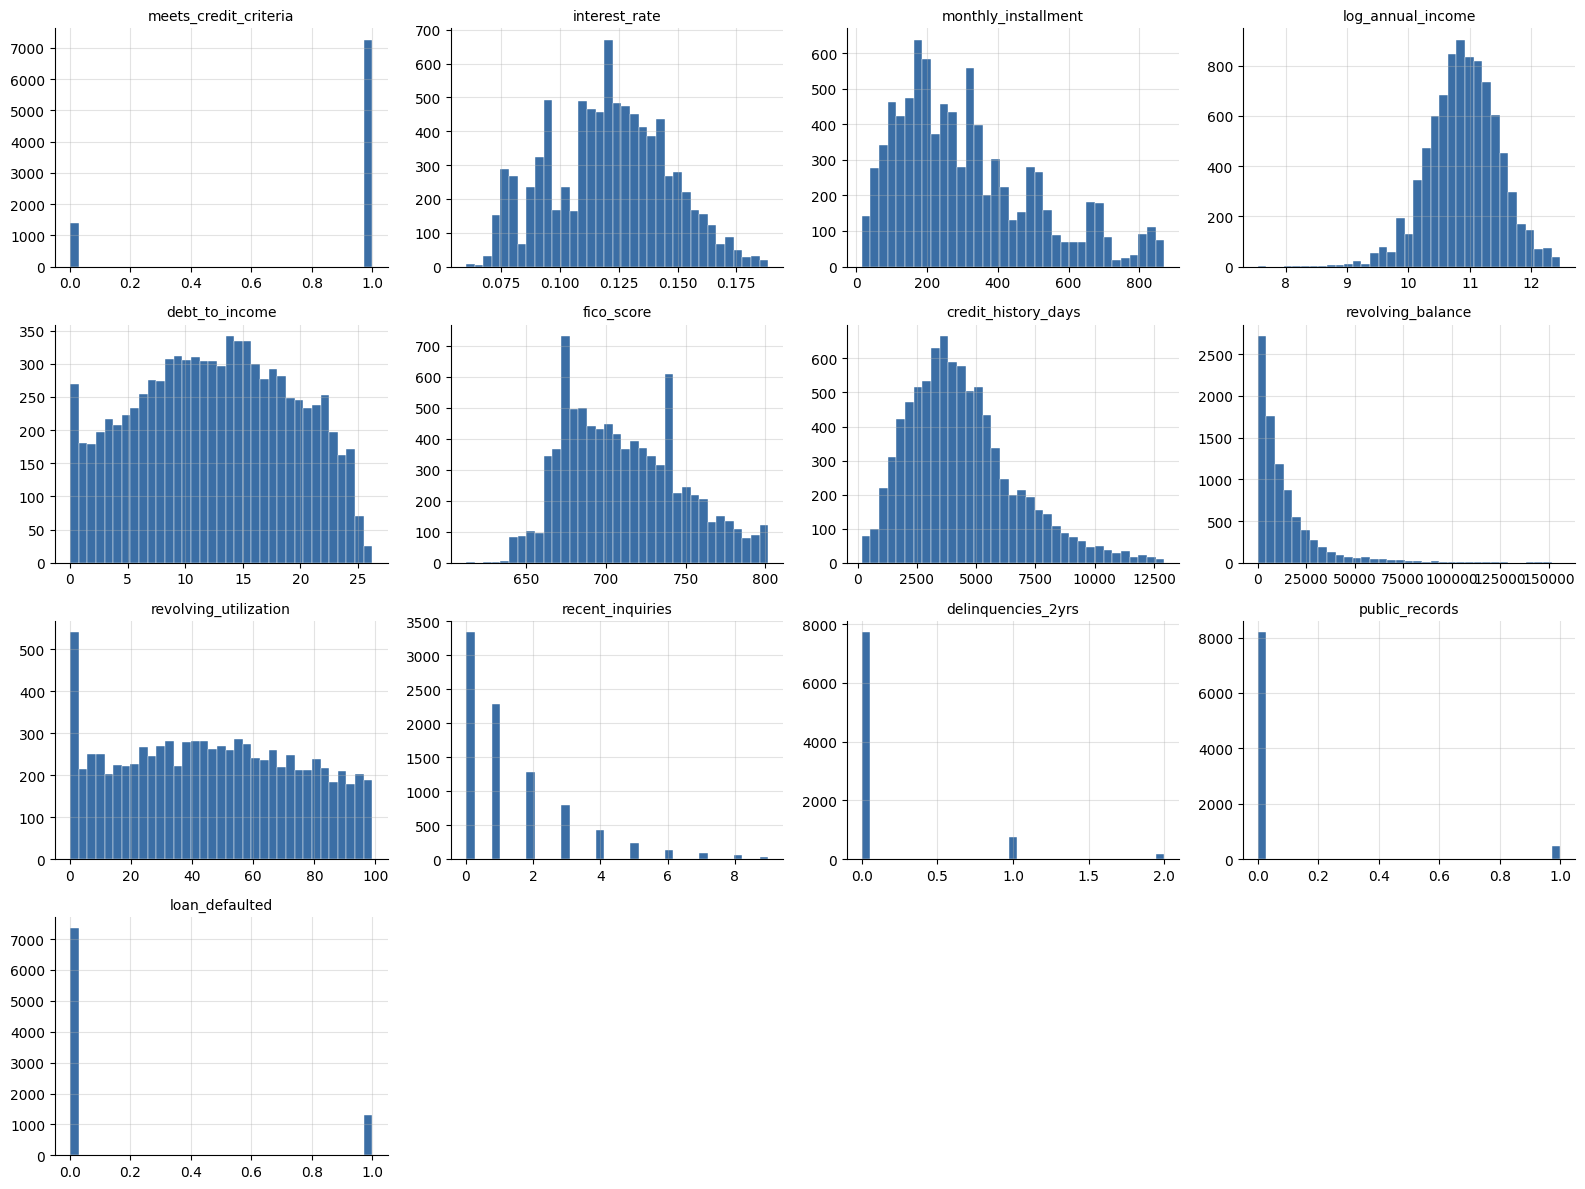

In [27]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col], bins=35, color="#3b6ea5", edgecolor="white", linewidth=.3)
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

- `interest_rate` and `fico_score` are now readable. The rate is roughly symmetric around 12% (the comb-like gaps come from rates being recorded in discrete steps). FICO is right-skewed, starts abruptly near 640 (it looks like a lending floor), and has spikes near 670 and 740 that are partly a binning effect of scores recorded in steps of 5. The raw plots in the first step were distorted only by those few bad rows.
- `log_annual_income` is close to normal, which is why it was stored as a log.
- `revolving_balance`, `credit_history_days`, `monthly_installment` and `recent_inquiries` are right-skewed. `delinquencies_2yrs` and `public_records` are heavily zero-inflated (most borrowers have none).
- `meets_credit_criteria` and `loan_defaulted` are binary. `revolving_utilization` is spread fairly evenly over 0–99 with a spike at zero, and `debt_to_income` has a similar spike at zero (borrowers reporting no debt or no revolving use).
- Linear regression does not require normal predictors, but the skewed ones (balance, history) may deserve a log transform if I wanted to squeeze out more accuracy.

### Interest rate vs FICO score

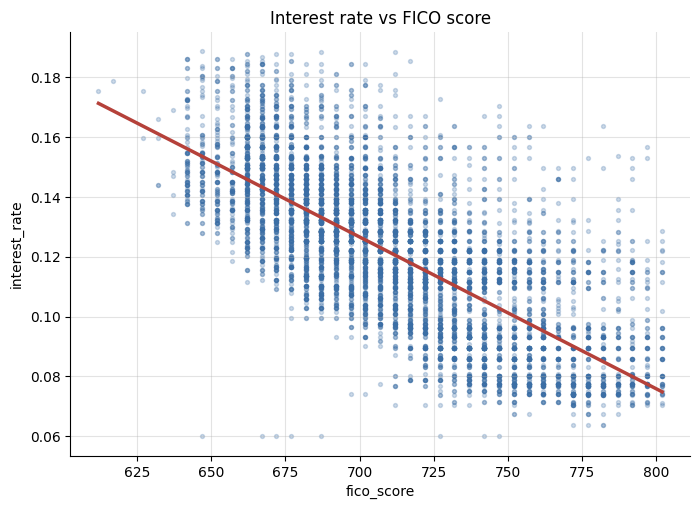

In [28]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(df["fico_score"], df["interest_rate"], s=8, alpha=.25, color="#3b6ea5")
slope, intercept = np.polyfit(df["fico_score"], df["interest_rate"], 1)
xs = np.array([df["fico_score"].min(), df["fico_score"].max()])
ax.plot(xs, intercept + slope * xs, color="#b5413a", lw=2.5)
ax.set_xlabel("fico_score"); ax.set_ylabel("interest_rate")
ax.set_title("Interest rate vs FICO score")
plt.show()

There is a clear downward trend (r = –0.74): higher FICO, lower rate. The cloud is wide at every FICO level, though, with a spread of several percentage points at a given score, so FICO alone leaves a lot unexplained. The vertical stripes are because scores come in steps of 5. At the top of the range rates seem to level off around 7–8%, so the straight line probably over-states the drop there. There is also a handful of loans at exactly 6% scattered across all scores, which looks like a rate floor rather than a credit effect. A straight line is a reasonable first model, not a perfect one.

### Loan defaults

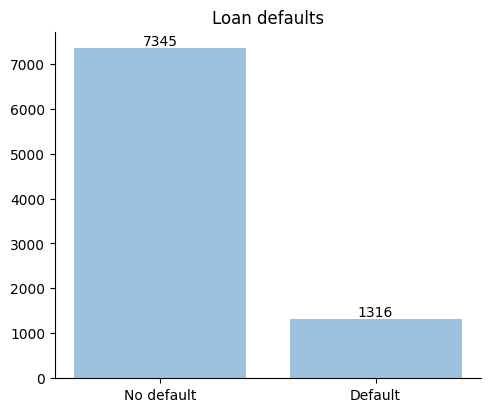

loan_defaulted
0    0.848
1    0.152
Name: proportion, dtype: float64


In [29]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
counts = df["loan_defaulted"].value_counts().sort_index()
ax.bar([0, 1], counts.values, color="#9ec1e0", width=.8)
ax.grid(False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["No default", "Default"]); ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Loan defaults")
plt.show()
print(df["loan_defaulted"].value_counts(normalize=True).round(3))

About 15% of loans defaulted, so the classes are imbalanced (roughly 85/15). That does not affect the interest-rate regression below, but it would matter for a default classifier, where plain accuracy would be misleading because always predicting "no default" scores about 85%.

## Task 8 – Predicting interest rate with linear regression

Four nested models. All use the split specified in the assignment, so every model is trained and tested on the same rows.

 Decisions  I made:
- The dataset's income column is `log_annual_income`, so that is the "annual income" variable.
- Loan purpose dummies use `drop_first=True`. Keeping all seven plus the intercept would create the dummy variable trap (perfect collinearity).
- The "full model" is every column except the target.

In [ ]:
y = df["interest_rate"]
purpose = pd.get_dummies(df["loan_purpose"], drop_first=True, dtype=int)

feature_sets = {
    "1. FICO only": df[["fico_score"]],
    "2. + log income": df[["fico_score", "log_annual_income"]],
    "3. + loan purpose": pd.concat([df[["fico_score", "log_annual_income"]], purpose], axis=1),
    "4. Full model": pd.concat([df.drop(columns=["interest_rate", "loan_purpose"]), purpose], axis=1),
}

rows, fitted = [], {}
for name, X_m in feature_sets.items():
    X_train, X_test, y_train, y_test = train_test_split(X_m, y, test_size=0.30, random_state=42)
    lr = LinearRegression().fit(X_train, y_train)
    pred = lr.predict(X_test)
    fitted[name] = (lr, X_m.columns)
    rows.append({"model": name, "features": X_m.shape[1],
                "train R2": r2_score(y_train, lr.predict(X_train)),
                "test R2": r2_score(y_test, pred),
                "test MSE": mean_squared_error(y_test, pred),
                 "test RMSE (pct pts)": np.sqrt(mean_squared_error(y_test, pred)) * 100})

results = pd.DataFrame(rows).set_index("model")
results.round(5)

,features,train R2,test R2,test MSE,test RMSE (pct pts)
model,,,,,
1. FICO only,1,0.54576,0.54043,0.00028,1.67307
2. + log income,2,0.56161,0.55453,0.00027,1.64721
3. + loan purpose,8,0.59270,0.58678,0.00025,1.58646
4. Full model,18,0.68746,0.66651,0.00020,1.42521


In [ ]:
# slope of model 1 in plain units: rate change for 10 more FICO points
lr1 = fitted["1. FICO only"][0]
print("model 1: 10 FICO points ->", round(lr1.coef_[0] * 10 * 100, 3), "percentage points of interest rate")

# sensitivity: full model without monthly_installment (it is mechanically tied to the rate.)
X_ns = feature_sets["4. Full model"].drop(columns="monthly_installment")
Xtr, Xte, ytr, yte = train_test_split(X_ns, y, test_size=0.30, random_state=42)
m_ns = LinearRegression().fit(Xtr, ytr)
print("full model without installment -> test R2:", round(r2_score(yte, m_ns.predict(Xte)), 4),
      "| test MSE:", round(mean_squared_error(yte, m_ns.predict(Xte)), 6))

### Which model is best?

| | What happens |
|---|---|
| Model 1 (FICO only) | Already explains about 54% of test variance. Ten more FICO points go with roughly half a percentage point lower interest rate. |
| Model 2 (+ income) | Small gain (R² about 0.555). Income adds little once credit score is known. |
| Model 3 (+ purpose) | Another step up (about 0.587). Small business and debt consolidation carry a premium. |
| Model 4 (full) | Clearly best: test R² about 0.667 and the lowest MSE (about 0.0002, an RMSE near 1.4 percentage points). |

**Best predictive model: Model 4.** Model 4 has the lowest test MSE and highest test R². Train and test R² are close (about 0.69 vs 0.67), so the extra features are not simply overfitting. The improvement from Model 3 to Model 4 is also larger than any earlier step, so the added variables carry real information. The installment check just above shows how much of that comes from a single column.

**A Caveat I would raise in a real setting.** `monthly_installment` is calculated from loan size, term and the interest rate, so including it lets the model partly see the answer. When I drop it, test R² falls to about 0.60, which is still better than Model 3 but a more honest estimate of what you can predict from borrower characteristics alone. `loan_defaulted` is also an outcome observed after the loan was priced, so it would not be available at the time a rate is quoted. If this model were meant for pricing new loans, I would use the full model without those two variables.

MSE values look tiny because the target is a fraction (0.12 rather than 12%). The RMSE column in percentage points is easier to read: moving from FICO only to the full model improves typical error from about 1.7 to about 1.4 points. Even the best linear model leaves a third of the variance unexplained, which fits the earlier scatterplot with its wide band.